# A05 六个团队怎样预约两间实验室？

团队各有可用时间、实验时长、房间要求和成员。输出一份不重叠、成员不分身的安排，并展示无解时该怎样描述。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 先列出每个团队的合法选项
一个预约用(room,start,end)表示，区间采用左闭右开：[1,3)与[3,4)不冲突。先过滤房间和可用时间，再解决团队间冲突。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

from ortools.sat.python import cp_model
jobs = [dict(name="光学组",duration=2,rooms=[0],starts=[0,1,2],members={"Li","Wu"}),
        dict(name="编程组",duration=1,rooms=[0,1],starts=[0,1,2,3],members={"Sun"}),
        dict(name="测试组",duration=2,rooms=[0,1],starts=[1,2,3,4],members={"Li"}),
        dict(name="阅读组",duration=1,rooms=[1],starts=[0,1,2,3],members={"Qian"}),
        dict(name="装配组",duration=2,rooms=[0,1],starts=[0,1,2,3,4],members={"Zhou"}),
        dict(name="演示组",duration=1,rooms=[0],starts=[3,4,5],members={"Sun"})]
def options(job):
    return [(room,start,start+job["duration"]) for room in job["rooms"] for start in job["starts"]]
def conflict(a, b, job_a, job_b):
    overlap = max(a[1],b[1]) < min(a[2],b[2])
    shared_resource = a[0] == b[0] or bool(job_a["members"] & job_b["members"])
    return overlap and shared_resource
assert not conflict((0,0,1),(0,1,2),jobs[0],jobs[1])
(DATA_DIR / "预约需求.json").write_text(json.dumps(jobs,ensure_ascii=False,default=list,indent=2),encoding="utf-8")


1052

## 2. 回溯寻找第一份合法计划
先安排选项少的团队。递归每增加一个预约就检查已安排团队，遇到冲突撤销选择。它有助于理解约束，不保证最小完工时间。

In [3]:
def backtrack_booking(requests):
    order = sorted(range(len(requests)),key=lambda i:len(options(requests[i])))
    plan = {}
    def visit(k):
        if k == len(order): return dict(plan)
        i = order[k]
        for choice in options(requests[i]):
            if all(not conflict(choice,other,requests[i],requests[j]) for j,other in plan.items()):
                plan[i] = choice
                found = visit(k+1)
                if found is not None: return found
                del plan[i]
        return None
    return visit(0)
baseline = backtrack_booking(jobs)
assert baseline is not None


## 3. 用CP-SAT选择互不冲突的选项
每个团队恰好选一个选项。冲突的两个选项不能同时被选中。我们最小化最后结束时刻；求解状态和预约合法性分开检查。

In [4]:
def solve_booking(requests):
    model=cp_model.CpModel(); candidates=[options(j) for j in requests]; variables={}
    for i,choices in enumerate(candidates):
        variables[i] = [model.new_bool_var(f"team{i}_option{k}") for k in range(len(choices))]
        model.add_exactly_one(variables[i])
    for i in range(len(requests)):
        for j in range(i+1,len(requests)):
            for k,a in enumerate(candidates[i]):
                for l,b in enumerate(candidates[j]):
                    if conflict(a,b,requests[i],requests[j]): model.add(variables[i][k]+variables[j][l] <= 1)
    horizon=max((c[2] for choices in candidates for c in choices),default=0)
    end=model.new_int_var(0,horizon,"end")
    for i,choices in enumerate(candidates):
        for k,c in enumerate(choices): model.add(end>=c[2]).only_enforce_if(variables[i][k])
    model.minimize(end)
    solver=cp_model.CpSolver(); solver.parameters.max_time_in_seconds=5; solver.parameters.num_search_workers=1
    state=solver.solve(model)
    result=({i:next(c for k,c in enumerate(choices) if solver.value(variables[i][k])) for i,choices in enumerate(candidates)}
            if state in (cp_model.OPTIMAL,cp_model.FEASIBLE) else None)
    return solver.status_name(state),result
def check_booking(plan,requests):
    if plan is None or set(plan)!=set(range(len(requests))): return False
    # 直接核对原始需求，不复用求解器生成选项或冲突约束的函数。
    for i,(room,start,end) in plan.items():
        request=requests[i]
        if room not in request['rooms'] or start not in request['starts']: return False
        if end-start!=request['duration']: return False
    for i in plan:
        for j in plan:
            if i>=j: continue
            a,b=plan[i],plan[j]
            if a[1]<b[2] and b[1]<a[2]:
                if a[0]==b[0]: return False
                if any(member in requests[j]['members'] for member in requests[i]['members']): return False
    return True
status,plan=solve_booking(jobs)
assert plan is not None, f"未获得预约表：{status}；UNKNOWN不等于无解。"
assert check_booking(plan,jobs) and check_booking(baseline,jobs)
corrupted=dict(plan); room,start,end=corrupted[0]; corrupted[0]=(room,start,end+1)
assert not check_booking(corrupted,jobs)
impossible=[dict(name=str(i),duration=1,rooms=[0],starts=[0],members={str(i)}) for i in range(2)]
bad_status,bad_plan=solve_booking(impossible)
assert bad_status=="INFEASIBLE" and bad_plan is None


## 4. 保存预约表与冲突反例
空结果不一定表示数学上无解：只有INFEASIBLE是证明无解。这个小例的冲突需求可通过增加房间或时间修复，但一般可能需要同时放宽多个条件。

In [5]:
table=pd.DataFrame([dict(team=jobs[i]["name"],room=c[0],start=c[1],end=c[2]) for i,c in plan.items()])
table.to_csv(OUT_DIR / "预约表.csv",index=False,encoding="utf-8-sig")
for i,c in plan.items():
    plt.barh(c[0],c[2]-c[1],left=c[1],height=.5,alpha=.7)
    plt.text((c[1]+c[2])/2,c[0],jobs[i]["name"],ha="center",va="center",fontsize=8)
plt.yticks([0,1],["实验室0","实验室1"]); plt.xlabel("时段")
plt.tight_layout(); plt.savefig(OUT_DIR / "预约安排.png"); plt.close()
end=max(c[2] for c in plan.values()); baseline_end=max(c[2] for c in baseline.values())
save_results({"status":status,"last_end":end,"backtracking_last_end":baseline_end,
              "constraint_check":True,"infeasible_example":bad_status},
             f"采用预约表中的方案，最后在时段{end}结束，回溯基线为{baseline_end}；状态{status}。"
             "房间重叠和成员分身均独立检查通过。若可用时间变化，应先更新需求再求解。")


{
  "status": "OPTIMAL",
  "last_end": 5,
  "backtracking_last_end": 6,
  "constraint_check": true,
  "infeasible_example": "INFEASIBLE"
}
采用预约表中的方案，最后在时段5结束，回溯基线为6；状态OPTIMAL。房间重叠和成员分身均独立检查通过。若可用时间变化，应先更新需求再求解。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

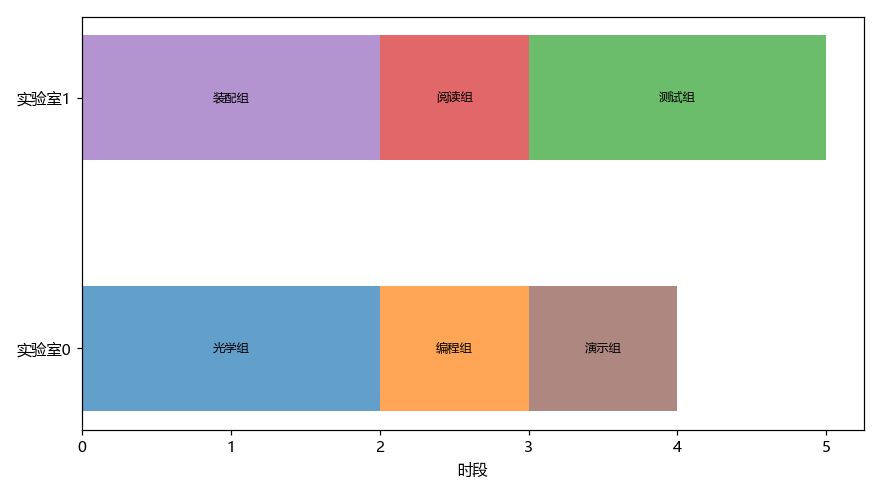

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
本例时间离散、时长固定且实验不可中断；成员共享也属于资源互斥。逐条放宽仅是诊断方法，不保证找到最少的修改。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。